## Lab 1: Choose a sound and analyze it
In this lab you will choose a sound to be used for all the labs and start imitating it with a single sinusoid.

In [12]:
import numpy as np
from util import load_audio, save_audio, plot_signals
from IPython.display import Audio

**Example signal**

As an example of what you will do in the labs let's ear a sound similar to the one you will use in class and a synthesized version of it.

In [13]:
reference, fs = load_audio('audio/reference.wav')
Audio(reference, rate=fs)

**Synthesis**

Now we can load and listen to a synthesised signal like the one you will obtain by the end of the course and that tries to imitate the example signal. This is an audio signal created from scratch only using the knowledge gained during the course.

In [14]:
synthesis, fs = load_audio('audio/synthesis.wav')
Audio(synthesis, rate=fs)

### 1. Choose a reference sound

1.1. Find a recording of a single plucked string sound. Be creative, do not choose “guitar” by default, nor copy a sound from another group. You should use [Freesound](https://freesound.org/) to find the recordings (Freesound is a huge collaborative database of audio snippets released under Creative Commons licenses created and maintained by researchers of the Music Technology Group of the UPF). Try to find a sound with the best possible quality. The ideal sound format should be: uncompress (such as.wav, .aiff, but no .mp3), mono (one channel) and with a sampling rate of  44100Hz. The sound file should also contain a single note. You can start by downloading a sound from freesound and modify it with Audacity to the right format and content.

Write your answer here. Include the Freesound link to the selected sound recording.

1.2. Create your own github repository and upload your edited audio file there:

1) Sing up to github using your UPF gmail account: https://github.com/

2) Create a repository called **sis1_name** for your own work 

3) Upload your edited audio file to the repository

You will use that repository later in the lab, so keep your own audio file there even if you run the notebook with the bundled fallback first.


1.3. Clone your own repository and load the audio file from it. To keep the notebook runnable before you have your own recording, the code below also includes a fallback to the bundled reference sound in `audio/`. For the actual lab work, replace the fallback path with the audio file from your own repository.

In [15]:
from pathlib import Path

# Clone your own repository and point filepath to your own audio file.
# !git clone https://github.com/your-username/sis1_name.git
# filepath = Path('./sis1_name/your_file.wav')

filepath = None
try:
    # If you have your own file in a cloned repository, uncomment and edit the line below.
    filepath = Path('./audio/audio_arpa.wav')
    if filepath is None:
        raise FileNotFoundError
    ref, fs = load_audio(filepath)
    print(f'Using audio file: {filepath}')
except FileNotFoundError:
    filepath = Path('audio/reference.wav')
    ref, fs = load_audio(filepath)
    print(f'Using bundled reference audio: {filepath}')

Using audio file: audio/audio_arpa.wav


Note that `load_audio` function returns two variables: the audio signal (as a one dimensional array of floating point numbers), and the sampling rate (as a integer number). Now we can plot the audio signal:

In [16]:
plot_signals(ref, fs)

You can use the zoom in tool to see more details.

You can also use Audio widget to listen the audio signal:

In [17]:
Audio(ref, rate=fs)

### 2. Measure the signal period and fundamental frequency

2.1. Measure the period length, in seconds, and the fundamental frequency, in Hz, of the sound you choose. You can use Audacity to measure the period by zooming into a stable portion of the sound. Then compute its inverse to find the fundamental frequency. Find the closest musical note (note name) of the measured frequency (use google).

[Write here the note name and the fundamental frequency in hertz]

2.2. Calculate the period from the frequency value using Python:


In [18]:
samples = 118
fs = 44100
period = samples / fs
print(f"The period of the signal is: {period} seconds")

f = 1 / period
print(f"The fundamental frequency is: {f} Hz")

The period of the signal is: 0.0026757369614512473 seconds
The fundamental frequency is: 373.728813559322 Hz


2.3. Plot three periods of the signal using the `plot_signals` function and selecting `t_start` and `t_end` arguments accordingly. Try to get the first periods of the audio signal but avoiding the attack section.

In [19]:
t_start = 0.2
t_end = t_start + (3 * period)
plot_signals(ref, fs, t_start=t_start, t_end=t_end)

2.4. Measure the period of the signal manually by identifying the begining and ending of a periodic cycle. Note that when you hover the mouse over one of the points in the plot, you can see the time and amplitude values. For instance, you can check the cross by zero.

I measured the period manually putting the mouse over the lowest point in the graph and writing the time, which was 0.2015202 seconds. Then, I did the same with the same point of the next cycle and saved its time as 0.204196 seconds. Then, I subtracted both values, finding that the period is 0.0026758 seconds, which matches the value of the period of the calculation I made earlier. 

2.5. Do the measured fundamental frequency you obtained and the frequency of the closest musical note coincide? If not, explain why.

No, they don't match perfectly because instruments like the harp are not perfectly tuned to exact mathematical notes. Also, when you play a note in an instrument, the sound can change a bit while it is fading away, which makes the measured frequency a bit different from the exact musical note.

### 3. Generating a sinusoid

3.1. Create a sinusoid of the same duration than the reference signal and same frequency than the fundamental frequency. Plot it along with the audio signal of the reference recording. Plot the same time segment that 2.3. Note that the sampling rate should be the same for both signals. Try to find the values of Amplitude and initial Phase that make the two signal segments plotted to match as close as possible (do not attempt to imitate the whole signal). Matching the phase is a bit tricky.



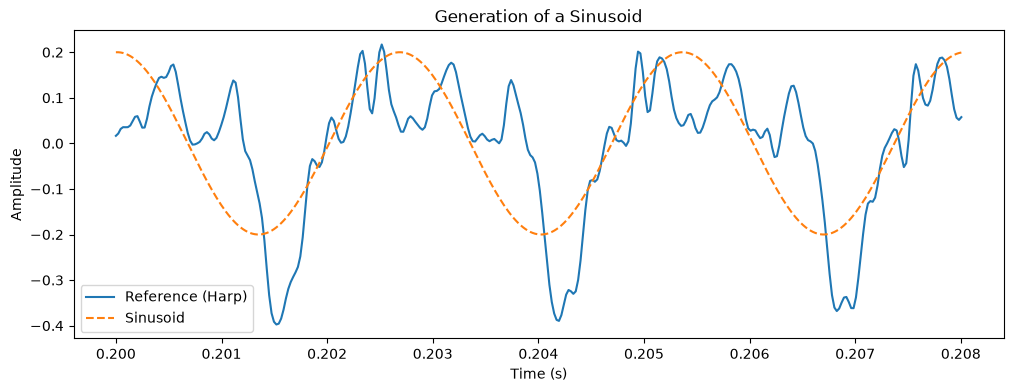

In [26]:
import matplotlib.pyplot as plt
t = np.arange(len(ref)) / fs

f0 = f
A=0.2
phi = 3.14

sinusoid = A * np.sin(2 * np.pi * f0 * t + phi)

start_idx = int(t_start * fs)
end_idx = int(t_end * fs)

plt.figure(figsize=(12, 4))
plt.plot(t[start_idx:end_idx], ref[start_idx:end_idx], label='Reference (Harp)')
plt.plot(t[start_idx:end_idx], sinusoid[start_idx:end_idx], label='Sinusoid', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Generation of a Sinusoid')
plt.legend()
plt.show()

3.2. What are the main differences between the two signals.

The main difference is that the signal of the harp is more complex, with multiple peaks inside each cycle. The sinusoid is more smooth and simple.

3.3. Save the synthesized signal using the 'save_audio` function:

In [27]:
save_audio('audio/synthesis_arpa.wav', sinusoid, fs)
print("Synthesized audio saved successfully.")

Synthesized audio saved successfully.
